In [1]:
import os
import random
import shutil
import subprocess
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

In [2]:
from utils_covidx import *

print("Using device:", DEVICE)

Using device: cuda


## 6. (contd.) Load saved model and recreate test dataset

In [3]:
def build_model():
    model = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)


disease_model = build_model()
disease_model = disease_model.eval()

optimizer = torch.optim.Adam(disease_model.parameters(), lr=2e-4)

checkpoint = torch.load(
    DATA / "disease_model_checkpoint.pth",
    weights_only=True,
    # map_location=DEVICE
)
disease_model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

In [4]:
test_df = read_txt(covid_test_images, covid_test_txt)
test_ds = COVIDxDataset(test_df, covid_test_images, eval_tf)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=True)

In [9]:
# Get a single batch. Re-run to get a different batch
batch = next(iter(test_loader))

background_idx = slice(None, 26)  # equivalent to [:26]
sample_idx = slice(26, 32)  # equivalent to [26:32]

## 7. XAI, part 1: Grad-CAM

[`pytorch-grad-cam`](https://github.com/jacobgil/pytorch-grad-cam) gives us Grad-CAM in a couple of lines. We target the last residual block (`layer4`), which is standard for ResNets.

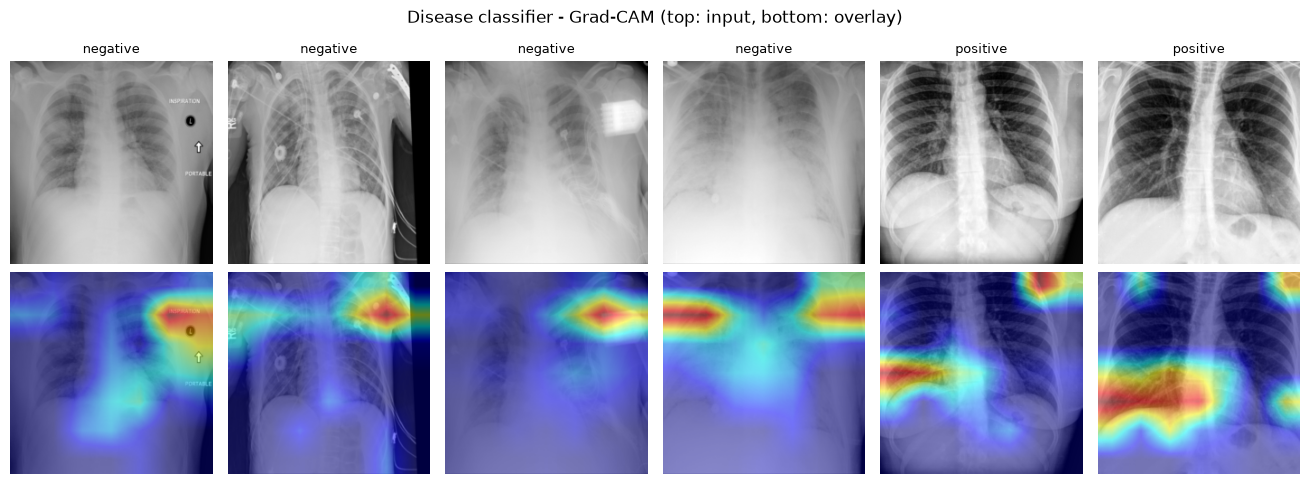

In [10]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from skimage.exposure import rescale_intensity

def make_gradcam(model):
    target_layers = [model.layer4[-1]]
    return GradCAM(model=model, target_layers=target_layers)


def denormalize(img_tensor: torch.Tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = img_tensor.permute(1, 2, 0).cpu().numpy()
    # Normalization: x_n = (x - mean) / std
    # De-Normalization: x = x_n * std + mean
    img = img * std + mean
    img -= img.min()
    img = rescale_intensity(img, in_range=(0, img.max()), out_range='float32')
    return img


def show_gradcam_grid(model, cam, batch, n=8, title=""):
    # random.seed(333)
    # idxs = random.sample(range(len(batch)), n)
    
    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5))

    images, labels =  batch
    sample_x, sample_y = images[sample_idx], labels[sample_idx]

    for col, (img_t, label) in enumerate(zip(sample_x, sample_y)):
        input_tensor = img_t.unsqueeze(0).to(DEVICE)
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]
        rgb_img = denormalize(img_t)
        overlay = show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True)

        axes[0, col].imshow(rgb_img); axes[0, col].axis("off")
        axes[0, col].set_title(CLASSES[label], fontsize=9)
        axes[1, col].imshow(overlay); axes[1, col].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


disease_cam = make_gradcam(disease_model)
show_gradcam_grid(
    disease_model, disease_cam, batch, n=6,
    title="Disease classifier - Grad-CAM (top: input, bottom: overlay)"
)

**What to look for:** if the hot regions sit inside the lung fields, that's reassuring. If they consistently sit on the image border, on embedded text/markers, on the diaphragm/rib edge only because that's where a crop boundary happens to fall, or anywhere clearly non-anatomical, that is the shortcut-learning signature DataRobot's post documents.

## 8. XAI, part 2: 

A rough lung-field mask (an ellipse in the center of the frame) lets us compute, per image, what fraction of the Grad-CAM energy falls **inside** that region vs. on the periphery. It's a crude proxy - a real audit would use an actual lung segmentation model - but it's enough to compare distributions across many images instead of squinting at eight examples.

In [11]:
def lung_roi_mask(h, w, cx_frac=0.5, cy_frac=0.55, rx_frac=0.32, ry_frac=0.38):
    yy, xx = np.mgrid[0:h, 0:w]
    cx, cy = w * cx_frac, h * cy_frac
    rx, ry = w * rx_frac, h * ry_frac
    return (((xx - cx) / rx) ** 2 + ((yy - cy) / ry) ** 2) <= 1.0


def roi_energy_fraction(cam_map, mask):
    cam_map = cam_map / (cam_map.sum() + 1e-8)
    return float(cam_map[mask].sum())


def score_dataset(model, cam, dataset, n=120):
    idxs = random.sample(range(len(dataset)), min(n, len(dataset)))
    rows = []
    for idx in idxs:
        img_t, label = dataset[idx]
        input_tensor = img_t.unsqueeze(0).to(DEVICE)
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0]
        mask = lung_roi_mask(*grayscale_cam.shape)
        frac = roi_energy_fraction(grayscale_cam, mask)
        rows.append({"label": CLASSES[label], "roi_energy_fraction": frac})
    return pd.DataFrame(rows)


roi_scores = score_dataset(disease_model, disease_cam, test_ds, n=120)
roi_scores.groupby("label")["roi_energy_fraction"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,60.0,0.246357,0.152724,0.050576,0.117050,0.218880,0.323603,0.813169
positive,60.0,0.415616,0.138882,0.069485,0.297304,0.452539,0.532844,0.643291


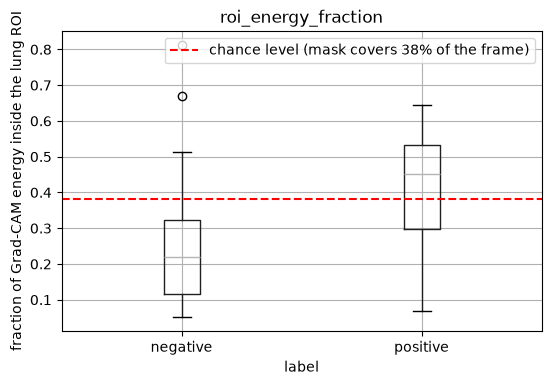

In [12]:
roi_mask_coverage = lung_roi_mask(IMAGE_SIZE, IMAGE_SIZE).mean()
fig, ax = plt.subplots(figsize=(6, 4))
roi_scores.boxplot(column="roi_energy_fraction", by="label", ax=ax)
ax.axhline(
    roi_mask_coverage, color="red", linestyle="--",
    label=f"chance level (mask covers {roi_mask_coverage:.0%} of the frame)"
)
ax.set_ylabel("fraction of Grad-CAM energy inside the lung ROI")
ax.legend()
plt.suptitle("")
plt.show()

If the boxes sit close to (or below) the red "chance level" line, the model's attention is, on average, no more concentrated on the lungs than a random blob would be - a strong quantitative hint of shortcut learning, consistent with what a purely visual Grad-CAM/SHAP inspection would suggest.

## 11. Optional: a second XAI method (SHAP) as a cross-check

###  11.1 SHAP: Gradient Explainer

Grad-CAM and SHAP can disagree, so it's worth corroborating with a different explanation method - this mirrors what the DataRobot post itself used. `GradientExplainer` on a handful of images is enough to sanity-check the Grad-CAM story; it is slow, so this cell is optional and capped at a small sample.

In [14]:
try:
    import shap

    images, labels = batch
    # background, _ = next(iter(test_loader))
    background = images[background_idx]
    explainer = shap.GradientExplainer(disease_model, background.to(DEVICE))

    sample_x, sample_y = images[sample_idx], labels[sample_idx]

    shap_values = explainer.shap_values(sample_x.to(DEVICE))
    sv = np.array(shap_values)
except Exception as e:
    # print("SHAP cross-check skipped:")
    raise RuntimeError() from e

In [15]:
shap_values.shape

(6, 3, 224, 224, 2)

In [28]:
shap_values.transpose([0, 2, 3, 1, 4]).shape

(6, 224, 224, 3, 2)

In [25]:
sample_x.shape

torch.Size([6, 3, 224, 224])

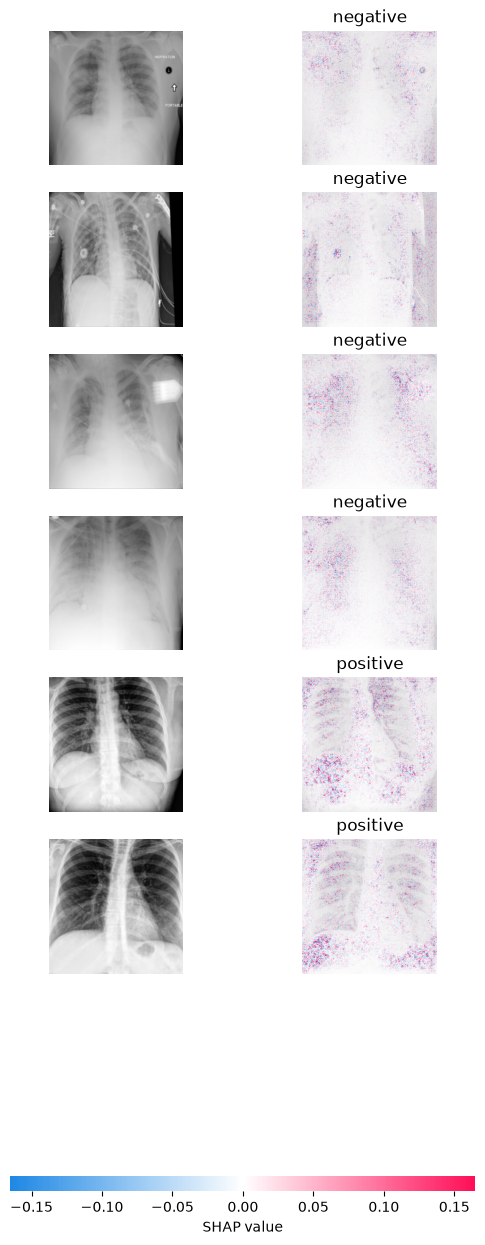

In [35]:
output = 1

shap.image_plot(
    sv2[..., output],
    np.array([denormalize(x) for x in sample_x]),
    [CLASSES[y] for y in sample_y.to('cpu').numpy()],
)

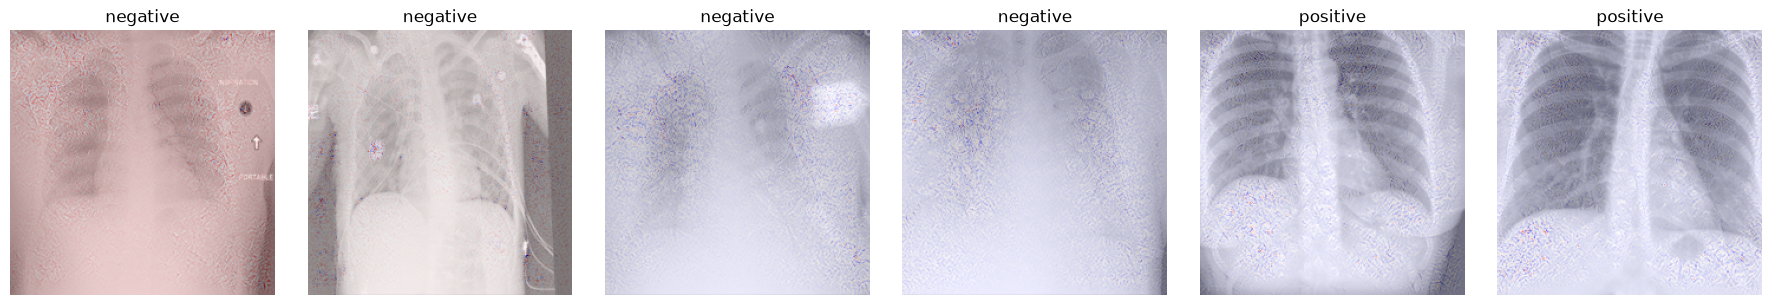

In [36]:
covid_idx = CLASS_TO_IDX["positive"]
batch_n = sample_x.shape[0]

# different shap versions return different layouts; detect which one we got
if sv.shape[0] == batch_n:
    # (batch, C, H, W, n_classes)
    get_map = lambda i: sv[i, ..., covid_idx].sum(axis=0)
else:
    # (n_classes, batch, C, H, W)
    get_map = lambda i: sv[covid_idx, i].sum(axis=0)

fig, axes = plt.subplots(1, batch_n, figsize=(3 * batch_n, 3))
for i, ax in enumerate(np.atleast_1d(axes)):
    ax.imshow(denormalize(sample_x[i]))
    ax.imshow(get_map(i), cmap="bwr", alpha=0.5)
    ax.set_title(CLASSES[sample_y[i].item()])
    ax.axis("off")
plt.tight_layout(); plt.show()

### 11.2 SHAP: Partition Explainer

In [37]:
from torch.nn.functional import softmax

# Wrapper: SHAP expects numpy inputs; we convert to torch and return probabilities
def predict_proba_numpy(x_np):
    """
    x_np: numpy array (B,H,W,C) in [0,1]
    returns: numpy array (B,10) probabilities
    """
    x = torch.tensor(x_np, dtype=torch.float32).permute(0,3,1,2).to(DEVICE)
    # x = torch.tensor(x_np).to(DEVICE)
    with torch.no_grad():
        logits = disease_model(x)
        probs = softmax(logits, dim=1).cpu().numpy()
    return probs


def batch_denormalize(img_tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    
    img = img_tensor.permute(0, 2, 3, 1).cpu().numpy()

    # Normalization: x_n = (x - mean) / std
    # De-Normalization: x = x_n * std + mean
    img = img * std + mean
    img -= img.min()
    img = rescale_intensity(img, in_range=(0, img.max()), out_range='float32')
    return img

PartitionExplainer explainer: 7it [00:23,  4.73s/it]                       


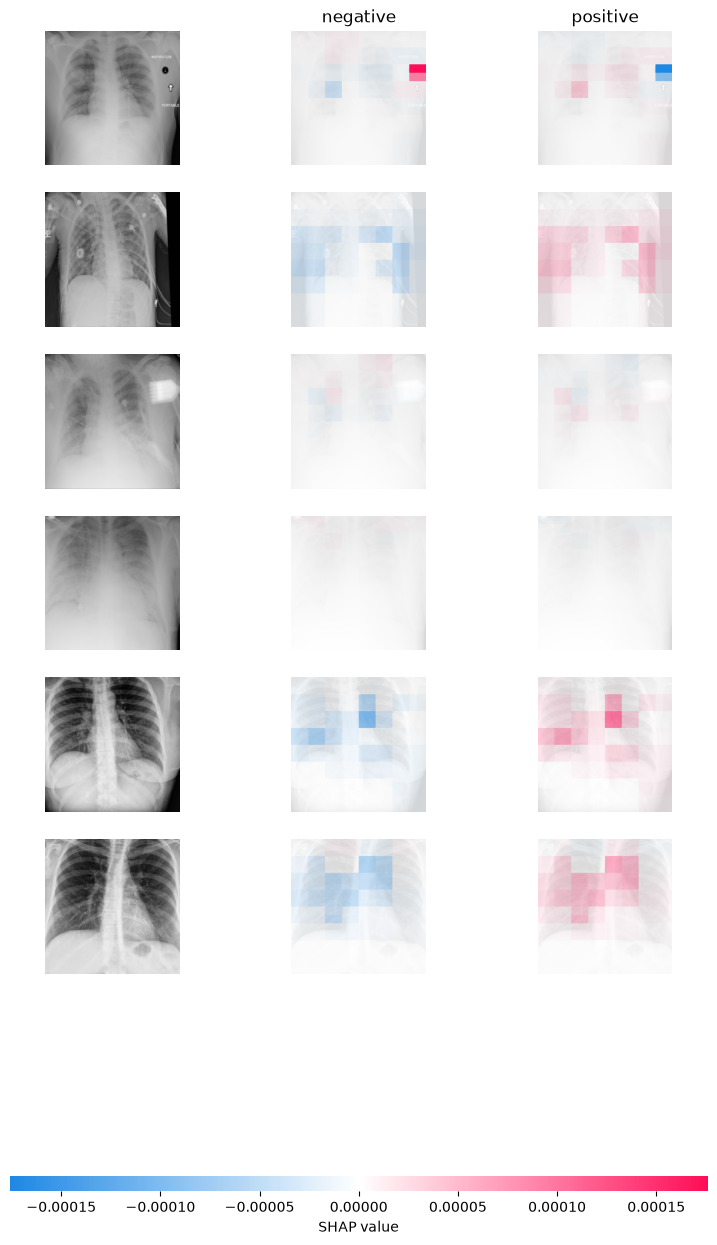

In [38]:
images, labels = batch

background = batch_denormalize(images[background_idx])
test_images = batch_denormalize(images[sample_idx])

# define a masker that is used to mask out partitions of the input image.
# SHAP image masker: uses inpainting / blurring style masking under the hood
masker = shap.maskers.Image("blur(64,64)", background[0].shape)
# masker = shap.maskers.Image(0.0, background[0].shape)  # no cv2 needed

# create an explainer with model and image masker
e = shap.Explainer(predict_proba_numpy, masker, output_names=CLASSES)

# here we explain 3 images using 500 evaluations of the underlying model to estimate the SHAP values
shap_values = e(test_images, max_eval=500, batch_size=BATCH_SIZE)

# plot the feature attributions
shap.image_plot(shap_values, test_images)

## 14. What this notebook demonstrates, and how to actually fix it

Discussion

**Further reading:**

- DataRobot, *"Identifying Leakage in Computer Vision on Medical Images"* ([archived version](https://web.archive.org/web/20240415132952/https://www.datarobot.com/blog/identifying-leakage-in-computer-vision-on-medical-images/))
- DeGrave, A.J., Janizek, J.D., Lee, S.-I. *"AI for radiographic COVID-19 detection selects shortcuts over signal."* Nature Machine Intelligence, 2021.
- Maguolo, G., Nanni, L. *"A critic evaluation of methods for COVID-19 automatic detection from X-ray images."* Information Fusion, 2021.
- Reference dataset-build notebook: [`y2ee201/Covid-x_ray-studies/create_COVIDx-datarobot.ipynb`](https://github.com/y2ee201/Covid-x_ray-studies/blob/master/create_COVIDx-datarobot.ipynb)